In [ ]:
# Import libraries
import pandas as pd
import numpy as np

# Load soccer dataset
df = pd.read_csv('soccer - 2020-09-24.csv')

# Explore dataset
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nPosition Distribution:")
print(df['Position'].value_counts())

df.head()

Dataset Shape: (571, 59)

Columns:
['Name', 'Jersey Number', 'Club', 'Position', 'Nationality', 'Age', 'Appearances', 'Wins', 'Losses', 'Goals', 'Goals per match', 'Headed goals', 'Goals with right foot', 'Goals with left foot', 'Penalties scored', 'Freekicks scored', 'Shots', 'Shots on target', 'Shooting accuracy %', 'Hit woodwork', 'Big chances missed', 'Clean sheets', 'Goals conceded', 'Tackles', 'Tackle success %', 'Last man tackles', 'Blocked shots', 'Interceptions', 'Clearances', 'Headed Clearance', 'Clearances off line', 'Recoveries', 'Duels won', 'Duels lost', 'Successful 50/50s', 'Aerial battles won', 'Aerial battles lost', 'Own goals', 'Errors leading to goal', 'Assists', 'Passes', 'Passes per match', 'Big chances created', 'Crosses', 'Cross accuracy %', 'Through balls', 'Accurate long balls', 'Saves', 'Penalties saved', 'Punches', 'High Claims', 'Catches', 'Sweeper clearances', 'Throw outs', 'Goal Kicks', 'Yellow cards', 'Red cards', 'Fouls', 'Offsides']

Position Distributi

,Name,Jersey Number,Club,Position,Nationality,Age,Appearances,Wins,Losses,Goals,...,Punches,High Claims,Catches,Sweeper clearances,Throw outs,Goal Kicks,Yellow cards,Red cards,Fouls,Offsides
0,Bernd Leno,1.0,Arsenal,Goalkeeper,Germany,28.0,64,28,16,0,...,34.0,26.0,17.0,28.0,375.0,489.0,2,0,0,NaN
1,Matt Macey,33.0,Arsenal,Goalkeeper,England,26.0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,NaN
2,Rúnar Alex Rúnarsson,13.0,Arsenal,Goalkeeper,Iceland,25.0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,NaN
3,Héctor Bellerín,2.0,Arsenal,Defender,Spain,25.0,160,90,37,7,...,NaN,NaN,NaN,NaN,NaN,NaN,23,0,125,8.0
4,Kieran Tierney,3.0,Arsenal,Defender,Scotland,23.0,16,7,5,1,...,NaN,NaN,NaN,NaN,NaN,NaN,2,0,9,0.0


In [ ]:
# Remove players with zero appearances
df_cleaned = df[df['Appearances'] > 0].copy()

# Select features available across all positions
features = [
    'Goals',
    'Assists',
    'Passes per match',
    'Yellow cards',
    'Red cards',
    'Fouls'
]

# Convert cumulative statistics to per-match statistics
for col in ['Goals', 'Assists', 'Yellow cards', 'Red cards', 'Fouls']:
    df_cleaned[col] = (
        df_cleaned[col] / df_cleaned['Appearances']
    )

# Features (X) and Target (y)
X = df_cleaned[features]
y = df_cleaned['Position']

print("Cleaned Dataset Shape:", df_cleaned.shape)
print("\nMissing Values:")
print(X.isnull().sum())

print("\nTarget Classes:")
print(y.value_counts())

X.head()

Cleaned Dataset Shape: (481, 59)

Missing Values:
Goals               0
Assists             0
Passes per match    0
Yellow cards        0
Red cards           0
Fouls               0
dtype: int64

Target Classes:
Position
Midfielder    178
Defender      156
Forward       101
Goalkeeper     46
Name: count, dtype: int64


,Goals,Assists,Passes per match,Yellow cards,Red cards,Fouls
0,0.000000,0.000000,27.86,0.031250,0.0,0.000000
3,0.043750,0.112500,44.53,0.143750,0.0,0.781250
4,0.062500,0.062500,32.44,0.125000,0.0,0.562500
6,0.068182,0.045455,54.91,0.409091,0.0,1.272727
7,0.000000,0.000000,53.66,0.195122,0.0,0.780488


In [ ]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=109,
    stratify=y
)

print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

Training Set: (336, 6)
Testing Set: (145, 6)


In [ ]:
# Import SVM and StandardScaler
from sklearn import svm
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Create SVM classifier
clf = make_pipeline(
    StandardScaler(),
    svm.SVC(kernel='linear')
)

# Train model
clf.fit(X_train, y_train)

# Predict test dataset
y_pred = clf.predict(X_test)

print("SVM Training Completed")

SVM Training Completed


In [ ]:
# Import evaluation metrics
from sklearn import metrics

# Model Accuracy
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.6344827586206897


In [ ]:
# Model Precision
print("Precision:",
      metrics.precision_score(
          y_test, y_pred,
          average='macro',
          zero_division=0
      ))

# Model Recall
print("Recall:",
      metrics.recall_score(
          y_test, y_pred,
          average='macro',
          zero_division=0
      ))

# Model F1 Score
print("F1 Score:",
      metrics.f1_score(
          y_test, y_pred,
          average='macro',
          zero_division=0
      ))

# Detailed classification report
print("\nClassification Report:")
print(metrics.classification_report(
    y_test, y_pred,
    zero_division=0
))

Precision: 0.7116393971381656
Recall: 0.6882500281436451
F1 Score: 0.697503306878307

Classification Report:
              precision    recall  f1-score   support

    Defender       0.59      0.62      0.60        47
     Forward       0.79      0.63      0.70        30
  Goalkeeper       0.93      0.93      0.93        14
  Midfielder       0.53      0.57      0.55        54

    accuracy                           0.63       145
   macro avg       0.71      0.69      0.70       145
weighted avg       0.64      0.63      0.64       145



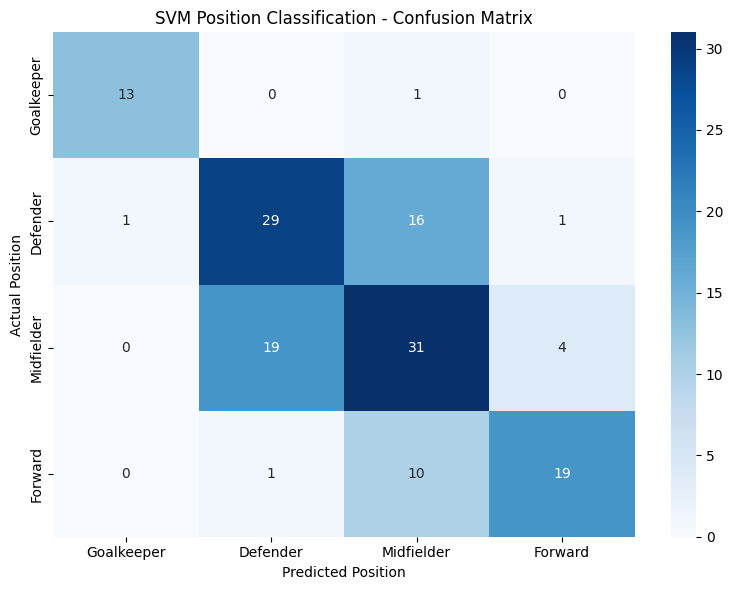

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Confusion Matrix
labels = ['Goalkeeper', 'Defender', 'Midfielder', 'Forward']

cm = metrics.confusion_matrix(
    y_test, y_pred,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Position")
plt.ylabel("Actual Position")
plt.title("SVM Position Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# Create extended dataset
df_extended = df[df['Appearances'] > 0].copy()

# Per-match features
for col in ['Goals', 'Assists', 'Yellow cards', 'Red cards', 'Fouls']:
    df_extended[col] = (
        df_extended[col] / df_extended['Appearances']
    )

# Goalkeeper-specific feature
# Missing saves for outfield players are treated as not applicable
df_extended['Saves_available'] = (
    df_extended['Saves'].notna().astype(int)
)

df_extended['Saves_per_match'] = (
    df_extended['Saves'].fillna(0)
    / df_extended['Appearances']
)

extended_features = features + [
    'Saves_per_match',
    'Saves_available'
]

X_ext = df_extended[extended_features]
y_ext = df_extended['Position']

# Train/Test Split
X_train_ext, X_test_ext, y_train_ext, y_test_ext = train_test_split(
    X_ext, y_ext,
    test_size=0.3,
    random_state=109,
    stratify=y_ext
)

# Extended SVM
clf_ext = make_pipeline(
    StandardScaler(),
    svm.SVC(kernel='linear')
)

clf_ext.fit(X_train_ext, y_train_ext)
y_pred_ext = clf_ext.predict(X_test_ext)

# Compare models
print("Basic SVM Accuracy:",
      metrics.accuracy_score(y_test, y_pred))

print("Extended SVM Accuracy:",
      metrics.accuracy_score(y_test_ext, y_pred_ext))

print("\nExtended Classification Report:")
print(metrics.classification_report(
    y_test_ext, y_pred_ext,
    zero_division=0
))

Basic SVM Accuracy: 0.6344827586206897
Extended SVM Accuracy: 0.6482758620689655

Extended Classification Report:
              precision    recall  f1-score   support

    Defender       0.60      0.64      0.62        47
     Forward       0.79      0.63      0.70        30
  Goalkeeper       1.00      1.00      1.00        14
  Midfielder       0.54      0.57      0.56        54

    accuracy                           0.65       145
   macro avg       0.73      0.71      0.72       145
weighted avg       0.66      0.65      0.65       145



### Summary (Sejin Lee)
(- Applied SVM to classify soccer players into four positions.
- Analyzed 481 players using a 70:30 train-test split.
- Basic SVM accuracy: 63.45%.
- Extended SVM accuracy: 64.83%.
- Goalkeepers were classified perfectly due to position-specific statistics.
- Midfielders were the most difficult to classify.
- Adding goalkeeper features slightly improved accuracy.)